# 4.5 Pearson Correlation Analysis

This notebook analyzes the relationship between network structure metrics and sentiment scores across time slots using Pearson correlation.

## Research Question
*How do network structure metrics (modularity, degree Gini, density, etc.) correlate with sentiment scores across pre-cancel, cancel, and post-apology windows?*

## Method
- **Correlation Method**: Pearson's r (measures linear relationship strength and direction)
- **Statistical Test**: `scipy.stats.pearsonr()` returns r-value and p-value
- **Data**: 21 time slots per person (pre-1 to pre-10, cancel-1, post-1 to post-10)
- **Significance Threshold**: α = 0.05
- **Subjects**: bodeoum_tv and mimiminu (combined comparison)

## Interpretation Guidelines
| |r| Value | Interpretation |
|---|---|---|
| 0.0 - 0.3 | Weak |
| 0.3 - 0.7 | Moderate |
| 0.7 - 1.0 | Strong |

## Phase 1: Configuration

### Configuration Overview
- Set up project paths and constants
- Define network metrics to analyze
- Configure persons to analyze (bodeoum_tv and mimiminu)

### Paths
- **Input Data**: Read from `03-analysis/outputs/{person}/`
- **Output Results**: Write to `04-evaluation/outputs/`
- **Output Figures**: Write to `04-evaluation/figures/`

### Network Metrics Analyzed
| Metric | Description |
|--------|-------------|
| modularity | Community separation (0=random, 1=highly separated) |
| degree_gini | Inequality in degree distribution (0=equal, 1=unequal) |
| density | Network connectivity |
| degree_variance | Variance in degree distribution |
| hub_dominance | max_degree / mean_degree ratio |
| cascade_depth | Longest reply chain |
| nodes | Number of users in network |
| edges | Number of reply relationships |
| in_degree_mean | Average in-degree (replies received) |
| num_communities | Number of detected conversation clusters |

In [1]:
import os
import pandas as pd
import numpy as np
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

def find_project_root():
    current = os.getcwd()
    while current != os.path.dirname(current):
        if os.path.exists(os.path.join(current, '02-preprocessing')):
            return current
        current = os.path.dirname(current)
    return os.getcwd()

PROJECT_DIR = find_project_root()

# Input data location (where processed data is stored)
INPUT_DIR = os.path.join(PROJECT_DIR, '03-analysis', 'outputs')

# Output location (where this notebook will write results)
OUTPUT_DIR = os.path.join(PROJECT_DIR, '04-evaluation', 'outputs')
FIGURE_DIR = os.path.join(PROJECT_DIR, '04-evaluation', 'figures')
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)

PERSONS = ['bodeoum_tv', 'mimiminu']

NETWORK_METRICS = [
    'modularity',
    'degree_gini',
    'density',
    'degree_variance',
    'hub_dominance',
    'cascade_depth',
    'nodes',
    'edges',
    'in_degree_mean',
    'num_communities'
]

print(f"Project root: {PROJECT_DIR}")
print(f"Input directory: {INPUT_DIR}")
print(f"Output directory: {OUTPUT_DIR}")
print(f"Figure directory: {FIGURE_DIR}")
print(f"Persons to analyze: {PERSONS}")
print(f"Network metrics: {NETWORK_METRICS}")

Project root: cancel-culture-sentiment-analysis
Input directory: cancel-culture-sentiment-analysis/03-analysis/outputs
Output directory: cancel-culture-sentiment-analysis/04-evaluation/outputs
Figure directory: cancel-culture-sentiment-analysis/04-evaluation/figures
Persons to analyze: ['bodeoum_tv', 'mimiminu']
Network metrics: ['modularity', 'degree_gini', 'density', 'degree_variance', 'hub_dominance', 'cascade_depth', 'nodes', 'edges', 'in_degree_mean', 'num_communities']


## Phase 2: Data Loading

### Data Sources
- **Sentiment data**: `03-analysis/outputs/{person}/sentiment_by_slot.csv`
  - Contains: slot, mean_sentiment, n_comments, pct_positive, pct_negative, pct_neutral
- **Network data**: `03-analysis/outputs/{person}/network_by_slot.csv`
  - Contains: slot and various network metrics

### Process
1. Load sentiment data for each person from 03-analysis/outputs/
2. Load network data for each person from 03-analysis/outputs/
3. Merge on 'slot' column
4. Display merged data structure

In [2]:
# ============================================================
# Phase 2: Data Loading
# ============================================================

def load_and_merge_data(person):
    """Load sentiment and network data, merge on slot."""
    sentiment_path = os.path.join(INPUT_DIR, person, 'sentiment_by_slot.csv')
    network_path = os.path.join(INPUT_DIR, person, 'network_by_slot.csv')
    
    sentiment_df = pd.read_csv(sentiment_path)
    network_df = pd.read_csv(network_path)
    
    # Rename 'name' column to 'slot' in network data for consistency
    if 'name' in network_df.columns:
        network_df = network_df.rename(columns={'name': 'slot'})
    
    # Select only the network metrics we need
    metrics_cols = ['slot'] + NETWORK_METRICS
    available_metrics = [c for c in metrics_cols if c in network_df.columns]
    network_df = network_df[available_metrics]
    
    # Merge on slot
    merged_df = pd.merge(sentiment_df, network_df, on='slot', how='inner')
    
    print(f"\n=== {person.upper()} ===")
    print(f"Sentiment data: {sentiment_df.shape}")
    print(f"Network data: {network_df.shape}")
    print(f"Merged data: {merged_df.shape}")
    
    return merged_df

merged_data = {}
for person in PERSONS:
    merged_data[person] = load_and_merge_data(person)

# Display sample of merged data for first person
print(f"\n=== Sample merged data (bodeoum_tv) ===")
sample_cols = ['slot', 'mean_sentiment'] + NETWORK_METRICS[:5]
print(merged_data['bodeoum_tv'][sample_cols].head(10).to_string(index=False))


=== BODEOUM_TV ===
Sentiment data: (21, 6)
Network data: (21, 11)
Merged data: (21, 16)

=== MIMIMINU ===
Sentiment data: (21, 6)
Network data: (21, 11)
Merged data: (21, 16)

=== Sample merged data (bodeoum_tv) ===
    slot  mean_sentiment  modularity  degree_gini  density  degree_variance  hub_dominance
cancel-1        0.805294    0.768715     0.765050 0.000087        85.704317     307.993744
  post-1        0.924907    0.840293     0.838561 0.002947        28.589084      85.772846
  post-2        0.873161    0.863718     0.893058 0.002681        27.047507      68.277487
  post-3        0.915329    0.797607     0.711149 0.024024         1.792549       6.937500
  post-4        0.891200    0.879591     0.770086 0.004695         7.291058      26.122642
  post-5        0.897069    0.681800     0.834576 0.014611        10.536053      29.500000
  post-6        0.845353    0.810345     0.895666 0.006665        12.898238      27.558621
  post-7        0.893612    0.828283     0.790043 0.019

## Phase 3: Pearson Correlation Computation

### Method
For each network metric, compute Pearson correlation with mean_sentiment:
- **r-value**: Correlation coefficient (-1 to +1)
  - Positive r: as metric increases, sentiment increases
  - Negative r: as metric increases, sentiment decreases
- **p-value**: Statistical significance (p < 0.05 = significant)

### Output
Results stored in a list with columns:
- person, metric, r_value, p_value, significant

In [3]:
# ============================================================
# Phase 3: Pearson Correlation Computation
# ============================================================

def compute_pearson_correlation(df, metric):
    """Compute Pearson correlation between sentiment and a network metric."""
    # Remove any NaN values
    valid_data = df[['mean_sentiment', metric]].dropna()
    
    if len(valid_data) < 3:
        return np.nan, np.nan
    
    r, p = pearsonr(valid_data['mean_sentiment'], valid_data[metric])
    return r, p

def interpret_correlation(r):
    """Interpret correlation strength based on |r| value."""
    abs_r = abs(r)
    if abs_r < 0.3:
        return 'Weak'
    elif abs_r < 0.7:
        return 'Moderate'
    else:
        return 'Strong'

results = []

for person in PERSONS:
    df = merged_data[person]
    for metric in NETWORK_METRICS:
        if metric in df.columns:
            r, p = compute_pearson_correlation(df, metric)
            significant = p < 0.05 if not np.isnan(p) else False
            interpretation = interpret_correlation(r) if not np.isnan(r) else 'N/A'
            
            results.append({
                'person': person,
                'metric': metric,
                'r_value': r,
                'p_value': p,
                'significant': significant,
                'interpretation': interpretation
            })

results_df = pd.DataFrame(results)

print("=== Pearson Correlation Results ===")
print(f"Total correlations computed: {len(results_df)}")
print(f"Significant correlations (p < 0.05): {results_df['significant'].sum()}")

=== Pearson Correlation Results ===
Total correlations computed: 20
Significant correlations (p < 0.05): 13


## Phase 4: Results Table

### Combined Results
Display correlation results for both persons side by side for comparison.

### Key Findings
- r-value shows direction and strength of linear relationship
- p-value indicates statistical significance
- Interpretation column categorizes |r| into weak/moderate/strong

In [4]:
# ============================================================
# Phase 4: Results Table
# ============================================================

print("=== Pearson Correlation Results by Person ===\n")

# Pivot table for better comparison
pivot_r = results_df.pivot(index='metric', columns='person', values='r_value')
pivot_p = results_df.pivot(index='metric', columns='person', values='p_value')
pivot_sig = results_df.pivot(index='metric', columns='person', values='significant')

comparison_df = pd.DataFrame({
    'metric': pivot_r.index,
    'r (bodeoum_tv)': pivot_r['bodeoum_tv'].values,
    'p (bodeoum_tv)': pivot_p['bodeoum_tv'].values,
    'sig (bodeoum_tv)': pivot_sig['bodeoum_tv'].values,
    'r (mimiminu)': pivot_r['mimiminu'].values,
    'p (mimiminu)': pivot_p['mimiminu'].values,
    'sig (mimiminu)': pivot_sig['mimiminu'].values
})

# Add interpretation columns
comparison_df['interp (bodeoum_tv)'] = comparison_df['r (bodeoum_tv)'].apply(
    lambda x: interpret_correlation(x) if not np.isnan(x) else 'N/A'
)
comparison_df['interp (mimiminu)'] = comparison_df['r (mimiminu)'].apply(
    lambda x: interpret_correlation(x) if not np.isnan(x) else 'N/A'
)

print("=== Combined Results Table ===")
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 10)
print(comparison_df.to_string(index=False))

# Highlight significant correlations
print("\n=== Significant Correlations (p < 0.05) ===")
sig_results = results_df[results_df['significant'] == True][['person', 'metric', 'r_value', 'p_value', 'interpretation']]
if len(sig_results) > 0:
    print(sig_results.to_string(index=False))
else:
    print("No statistically significant correlations found at p < 0.05")

=== Pearson Correlation Results by Person ===

=== Combined Results Table ===
         metric  r (bodeoum_tv)  p (bodeoum_tv)  sig (bodeoum_tv)  r (mimiminu)  p (mimiminu)  sig (mimiminu) interp (bodeoum_tv) interp (mimiminu)
  cascade_depth       -0.599576        0.004069              True     -0.584749      0.005367            True            Moderate          Moderate
    degree_gini        0.083137        0.720137             False     -0.265395      0.244942           False                Weak              Weak
degree_variance       -0.368047        0.100686             False     -0.533426      0.012765            True            Moderate          Moderate
        density        0.342636        0.128393             False      0.735536      0.000145            True            Moderate            Strong
          edges       -0.448136        0.041613              True     -0.681316      0.000672            True            Moderate          Moderate
  hub_dominance       -0.402222   

## Phase 5: Visualization

### Visualizations Created
1. **Grouped Bar Chart**: r-values for each metric, bars grouped by person
   - Color coding: green = significant (p < 0.05), gray = not significant
2. **Heatmap**: Correlation matrix showing r-values across all metrics

### Interpretation
- Positive r (right bar): as network metric increases, sentiment increases
- Negative r (left bar): as network metric increases, sentiment decreases
- Bar length indicates strength of correlation

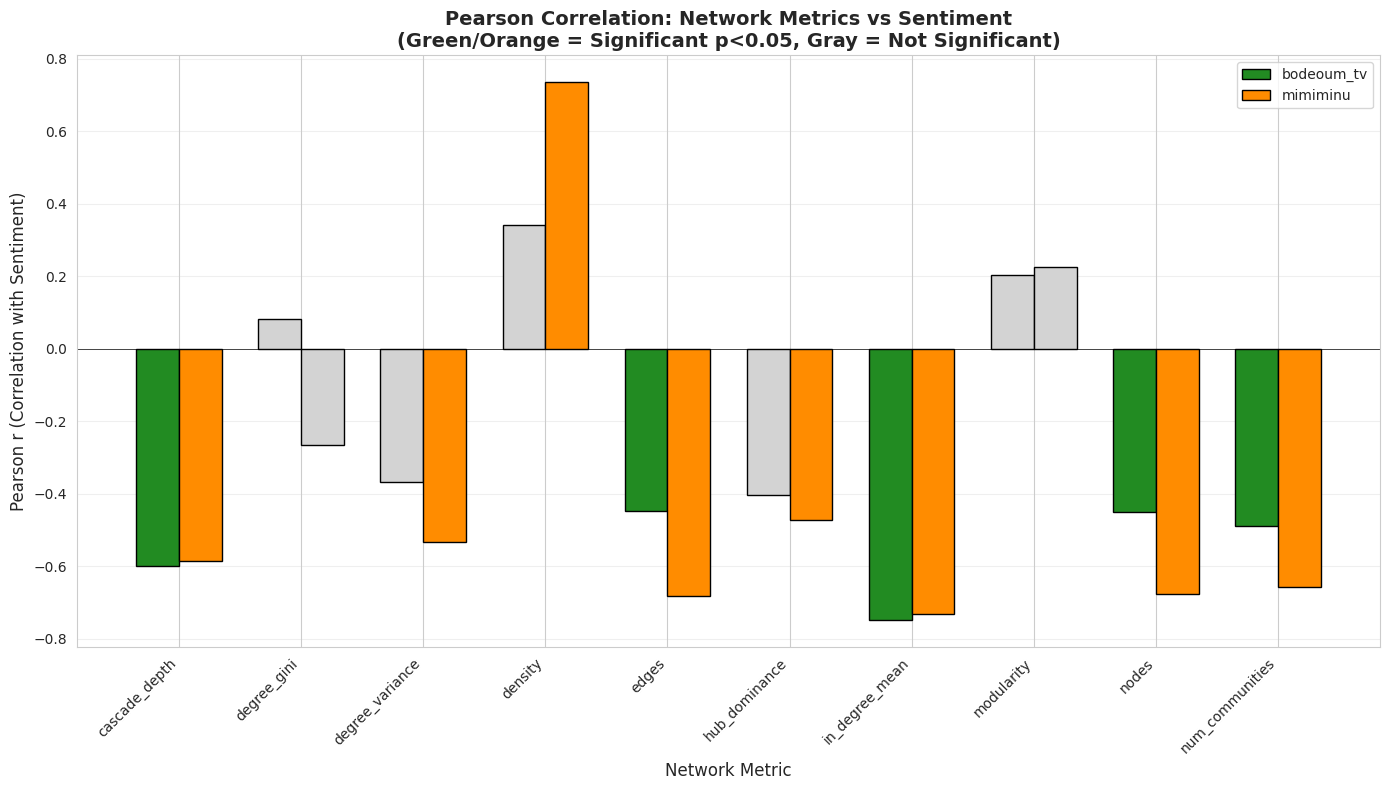

Saved: cancel-culture-sentiment-analysis/04-evaluation/figures/pearson_correlation_comparison.png


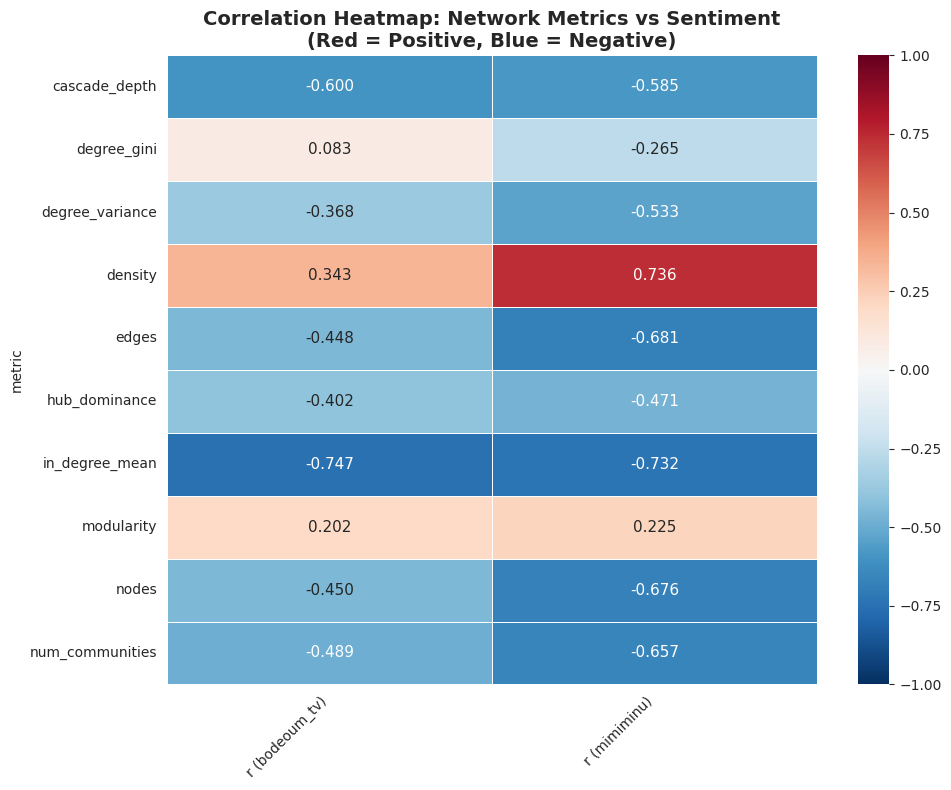

Saved: cancel-culture-sentiment-analysis/04-evaluation/figures/pearson_correlation_heatmap.png


In [5]:
# ============================================================
# Phase 5: Visualization
# ============================================================

os.makedirs(FIGURE_DIR, exist_ok=True)

# Figure 1: Grouped Bar Chart - Comparison of r-values
fig1, ax1 = plt.subplots(figsize=(14, 8))

metrics = comparison_df['metric'].tolist()
x = np.arange(len(metrics))
width = 0.35

r_bodeoum = comparison_df['r (bodeoum_tv)'].values
r_mimiminu = comparison_df['r (mimiminu)'].values
sig_bodeoum = comparison_df['sig (bodeoum_tv)'].values
sig_mimiminu = comparison_df['sig (mimiminu)'].values

# Color by significance
colors_bodeoum = ['forestgreen' if sig else 'lightgray' for sig in sig_bodeoum]
colors_mimiminu = ['darkorange' if sig else 'lightgray' for sig in sig_mimiminu]

bars1 = ax1.bar(x - width/2, r_bodeoum, width, label='bodeoum_tv', color=colors_bodeoum, edgecolor='black')
bars2 = ax1.bar(x + width/2, r_mimiminu, width, label='mimiminu', color=colors_mimiminu, edgecolor='black')

ax1.set_xlabel('Network Metric', fontsize=12)
ax1.set_ylabel('Pearson r (Correlation with Sentiment)', fontsize=12)
ax1.set_title('Pearson Correlation: Network Metrics vs Sentiment\n(Green/Orange = Significant p<0.05, Gray = Not Significant)', fontsize=14, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(metrics, rotation=45, ha='right')
ax1.legend(loc='best')
ax1.axhline(y=0, color='black', linestyle='-', linewidth=0.5)
ax1.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, 'pearson_correlation_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: {os.path.join(FIGURE_DIR, 'pearson_correlation_comparison.png')}")

# Figure 2: Heatmap of correlations
fig2, ax2 = plt.subplots(figsize=(10, 8))

heatmap_data = comparison_df[['metric', 'r (bodeoum_tv)', 'r (mimiminu)']].set_index('metric')
sns.heatmap(heatmap_data, annot=True, fmt='.3f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, ax=ax2, linewidths=0.5,
            annot_kws={'fontsize': 11})
ax2.set_title('Correlation Heatmap: Network Metrics vs Sentiment\n(Red = Positive, Blue = Negative)', fontsize=14, fontweight='bold')
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=45, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, 'pearson_correlation_heatmap.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: {os.path.join(FIGURE_DIR, 'pearson_correlation_heatmap.png')}")

## Phase 6: Export

### Export Files
| File | Description |
|------|-------------|
| `pearson_correlation_results.csv` | Full results with all metrics, r-values, p-values, significance |
| `pearson_correlation_comparison.csv` | Side-by-side comparison table |
| `pearson_correlation_comparison.png` | Grouped bar chart comparison |
| `pearson_correlation_heatmap.png` | Correlation heatmap |

In [6]:
# ============================================================
# Phase 6: Export
# ============================================================

# Export correlation results
export_path = os.path.join(OUTPUT_DIR, 'pearson_correlation_results.csv')
results_df.to_csv(export_path, index=False)
print(f"Exported: {export_path}")

# Export comparison table
comparison_path = os.path.join(OUTPUT_DIR, 'pearson_correlation_comparison.csv')
comparison_df.to_csv(comparison_path, index=False)
print(f"Exported: {comparison_path}")

print("\n=== EXPORT SUMMARY ===")
print(f"Project: {PROJECT_DIR}")
print(f"Persons analyzed: {PERSONS}")
print(f"Network metrics: {len(NETWORK_METRICS)}")
print(f"Total correlations: {len(results_df)}")
print(f"Significant: {results_df['significant'].sum()}")
print(f"\nOutput files:")
print(f"  - {export_path}")
print(f"  - {comparison_path}")
print(f"  - {os.path.join(FIGURE_DIR, 'pearson_correlation_comparison.png')}")
print(f"  - {os.path.join(FIGURE_DIR, 'pearson_correlation_heatmap.png')}")

Exported: cancel-culture-sentiment-analysis/04-evaluation/outputs/pearson_correlation_results.csv
Exported: cancel-culture-sentiment-analysis/04-evaluation/outputs/pearson_correlation_comparison.csv

=== EXPORT SUMMARY ===
Project: cancel-culture-sentiment-analysis
Persons analyzed: ['bodeoum_tv', 'mimiminu']
Network metrics: 10
Total correlations: 20
Significant: 13

Output files:
  - cancel-culture-sentiment-analysis/04-evaluation/outputs/pearson_correlation_results.csv
  - cancel-culture-sentiment-analysis/04-evaluation/outputs/pearson_correlation_comparison.csv
  - cancel-culture-sentiment-analysis/04-evaluation/figures/pearson_correlation_comparison.png
  - cancel-culture-sentiment-analysis/04-evaluation/figures/pearson_correlation_heatmap.png


## Summary

### RQ2 Answer Framework
Pearson correlation analysis provides:
- **Direction**: Positive r = metric increases with sentiment; Negative r = inverse relationship
- **Strength**: Weak (|r|<0.3), Moderate (0.3≤|r|<0.7), Strong (|r|≥0.7)
- **Significance**: p < 0.05 indicates statistically significant relationship

### Key Insights
- Compare results across both persons to identify consistent patterns
- Look for network metrics with significant correlations across both subjects
- Consider effect size (r² = r²) for practical significance

### Limitations
- Pearson r only captures linear relationships
- Small sample size (n=21 slots) limits statistical power
- Correlation does not imply causation